In [ ]:

import os

print(os.listdir("/content"))

['.config', 'mock_fraud_dataset_1000_rows (1).xlsx', 'sample_data']


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/mock_fraud_dataset_1000_rows (1).xlsx
/content/.config/active_config
/content/.config/default_configs.db
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/config_sentinel
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_update_check.json
/content/.config/.last_survey_prompt.yaml
/content/.config/gce
/content/.config/configurations/config_default
/content/.config/logs/2026.10.02/13.50.08.874802.log
/content/.config/logs/2026.10.02/13.50.15.366402.log
/content/.config/logs/2026.10.02/13.50.21.555054.log
/content/.config/logs/2026.10.02/13.49.46.128557.log
/content/.config/logs/2026.10.02/13.50.14.261149.log
/content/.config/logs/2026.10.02/13.50.21.004336.log
/content/sample_data/README.md
/content/sample_data/anscombe.json
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "/content/mock_fraud_dataset_1000_rows (1).xlsx"

df_original = pd.read_excel(file_path)

print("Dataset shape:", df_original.shape)
print("Missing values:", df_original.isnull().sum().sum())
print("Duplicate rows:", df_original.duplicated().sum())
print("Fraud transactions:", df_original["is_fraud"].sum())
print("Fraud rate (%):", round(df_original["is_fraud"].mean() * 100, 2))

display(df_original.head())

Dataset shape: (1000, 23)
Missing values: 0
Duplicate rows: 0
Fraud transactions: 69
Fraud rate (%): 6.9


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2025-01-01 00:15:00,1000000000000521,Thompson Inc,food_delivery,43.51,Jamie,Davis,F,947 Main Street,...,20.1784,73.1311,2828217,Student,1975-04-24,TXN100000000,1735690500,21.6520,74.1850,0
1,1,2025-01-01 00:48:00,1000000000000737,Morar Inc,shopping_net,75.99,Avery,Gupta,M,35 Main Street,...,22.0340,77.7846,1814239,Engineer,1997-07-16,TXN100000001,1735692480,21.5473,79.8402,0
2,2,2025-01-01 00:56:00,1000000000000740,Berge LLC,grocery_net,9.73,Jamie,Patel,F,494 Main Street,...,24.5435,80.5568,1389083,Analyst,1979-06-01,TXN100000002,1735692960,26.4358,81.2613,0
3,3,2025-01-01 04:06:00,1000000000000660,Walker Group,health_fitness,134.58,Jordan,Wilson,M,553 Main Street,...,28.3537,87.9396,1260368,Salesperson,1961-08-14,TXN100000003,1735704360,29.7208,87.8120,0
4,4,2025-01-01 04:20:00,1000000000000411,Huels-Hyatt,grocery_net,75.26,Alex,Brown,M,853 Main Street,...,27.6131,79.5925,1790081,Accountant,1977-03-09,TXN100000004,1735705200,26.8865,79.3937,0


In [ ]:
#clean the Dataset

# Keep the original dataset unchanged
df_clean = df_original.copy()

# Remove the exported DataFrame index column
if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Convert date columns to proper datetime types
df_clean["trans_date_trans_time"] = pd.to_datetime(
    df_clean["trans_date_trans_time"], errors="coerce"
)
df_clean["dob"] = pd.to_datetime(
    df_clean["dob"], errors="coerce"
)

# Check data types and quality
print("Cleaned shape:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate transaction IDs:")
print(df_clean["trans_num"].duplicated().sum())

print("\nFraud label values:")
print(sorted(df_clean["is_fraud"].dropna().unique()))

print("\nData types:")
print(df_clean.dtypes)

Cleaned shape: (1000, 22)

Missing values after cleaning:
0

Duplicate transaction IDs:
0

Fraud label values:
[np.int64(0), np.int64(1)]

Data types:
trans_date_trans_time    datetime64[ns]
cc_num                            int64
merchant                         object
category                         object
amt                             float64
first                            object
last                             object
gender                           object
street                           object
city                             object
state                            object
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                              object
dob                      datetime64[ns]
trans_num                        object
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud 

In [ ]:
#Feature engineering


# 1. Time-based features
df_clean["hour"] = df_clean["trans_date_trans_time"].dt.hour
df_clean["day_of_week"] = df_clean["trans_date_trans_time"].dt.day_name()
df_clean["weekday_num"] = df_clean["trans_date_trans_time"].dt.dayofweek
df_clean["is_weekend"] = (df_clean["weekday_num"] >= 5).astype(int)
df_clean["month"] = df_clean["trans_date_trans_time"].dt.month

# 2. Time period
df_clean["time_period"] = pd.cut(
    df_clean["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# 3. Customer age at transaction time
df_clean["age"] = (
    df_clean["trans_date_trans_time"].dt.year
    - df_clean["dob"].dt.year
)

# Adjust if the birthday had not occurred yet that year
birthday_not_reached = (
    (df_clean["trans_date_trans_time"].dt.month < df_clean["dob"].dt.month)
    | (
        (df_clean["trans_date_trans_time"].dt.month == df_clean["dob"].dt.month)
        & (df_clean["trans_date_trans_time"].dt.day < df_clean["dob"].dt.day)
    )
)
df_clean.loc[birthday_not_reached, "age"] -= 1

# 4. Customer-to-merchant distance in kilometres
def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))

df_clean["distance_km"] = haversine_distance(
    df_clean["lat"],
    df_clean["long"],
    df_clean["merch_lat"],
    df_clean["merch_long"]
)

# 5. Verify the new features
new_features = [
    "hour", "day_of_week", "is_weekend", "month",
    "time_period", "age", "distance_km"
]

print("New features created:")
print(new_features)

display(df_clean[new_features + ["amt", "is_fraud"]].head(10))
print("\nFinal shape:", df_clean.shape)

New features created:
['hour', 'day_of_week', 'is_weekend', 'month', 'time_period', 'age', 'distance_km']


,hour,day_of_week,is_weekend,month,time_period,age,distance_km,amt,is_fraud
0,0,Wednesday,0,1,Night,49,197.055947,43.51,0
1,0,Wednesday,0,1,Night,27,219.028681,75.99,0
2,0,Wednesday,0,1,Night,45,221.976339,9.73,0
3,4,Wednesday,0,1,Night,63,152.519851,134.58,0
4,4,Wednesday,0,1,Night,47,83.149923,75.26,0
5,5,Wednesday,0,1,Night,30,97.623305,27.46,0
6,7,Wednesday,0,1,Morning,58,184.075195,108.83,0
7,8,Wednesday,0,1,Morning,34,197.737105,33.00,0
8,9,Wednesday,0,1,Morning,24,178.249565,28.04,1
9,9,Wednesday,0,1,Morning,64,189.315657,59.16,0



Final shape: (1000, 30)


In [ ]:

print("Total columns:", len(df_clean.columns))
print(df_clean.columns.tolist())

Total columns: 30
['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud', 'hour', 'day_of_week', 'weekday_num', 'is_weekend', 'month', 'time_period', 'age', 'distance_km']


,hour,transactions,fraud_transactions,fraud_rate_pct,risk_multiplier
22,22,39,7,17.95,2.60
0,0,49,8,16.33,2.37
2,2,43,6,13.95,2.02
1,1,48,6,12.50,1.81
23,23,47,5,10.64,1.54
17,17,44,4,9.09,1.32
14,14,45,4,8.89,1.29
11,11,46,4,8.70,1.26
3,3,35,3,8.57,1.24
20,20,42,3,7.14,1.03


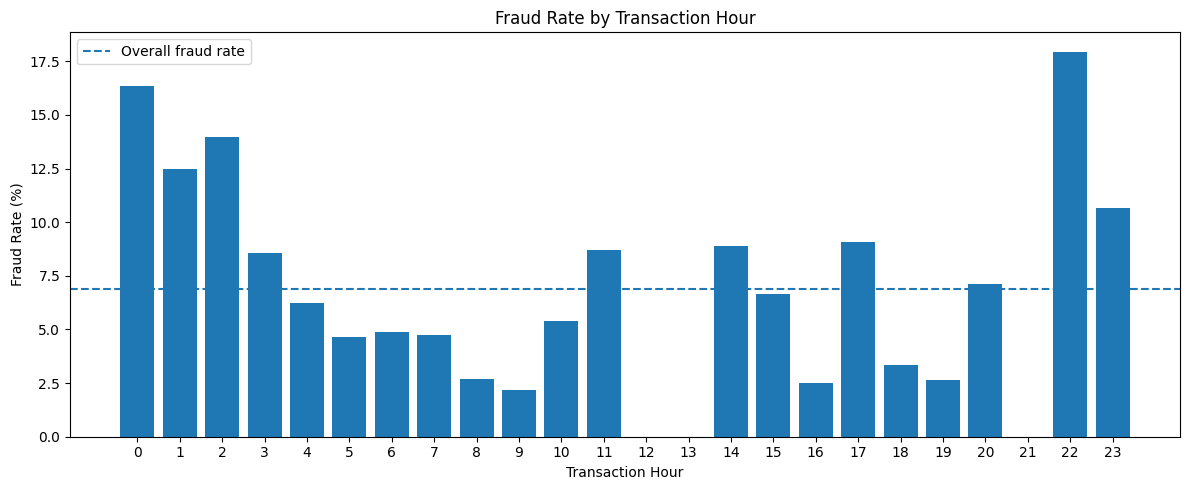

In [ ]:
#Time-based fraud analysis

# Overall fraud rate
overall_fraud_rate = df_clean["is_fraud"].mean()

# Analyze fraud by hour
hour_analysis = (
    df_clean.groupby("hour", observed=True)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

hour_analysis["fraud_rate_pct"] = (
    hour_analysis["fraud_transactions"]
    / hour_analysis["transactions"] * 100
).round(2)

hour_analysis["risk_multiplier"] = (
    hour_analysis["fraud_rate_pct"]
    / (overall_fraud_rate * 100)
).round(2)

display(
    hour_analysis.sort_values(
        "fraud_rate_pct", ascending=False
    )
)

# Plot fraud rate by hour
plt.figure(figsize=(12, 5))
plt.bar(hour_analysis["hour"], hour_analysis["fraud_rate_pct"])
plt.axhline(
    overall_fraud_rate * 100,
    linestyle="--",
    label="Overall fraud rate"
)
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Transaction Hour")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

,day_of_week,transactions,fraud_transactions,fraud_rate_pct,risk_multiplier,day_name
5,Tuesday,125,13,10.40,1.51,NaN
6,Wednesday,134,12,8.96,1.30,NaN
4,Thursday,147,13,8.84,1.28,NaN
3,Sunday,152,10,6.58,0.95,NaN
2,Saturday,145,9,6.21,0.90,NaN
1,Monday,151,8,5.30,0.77,NaN
0,Friday,146,4,2.74,0.40,NaN


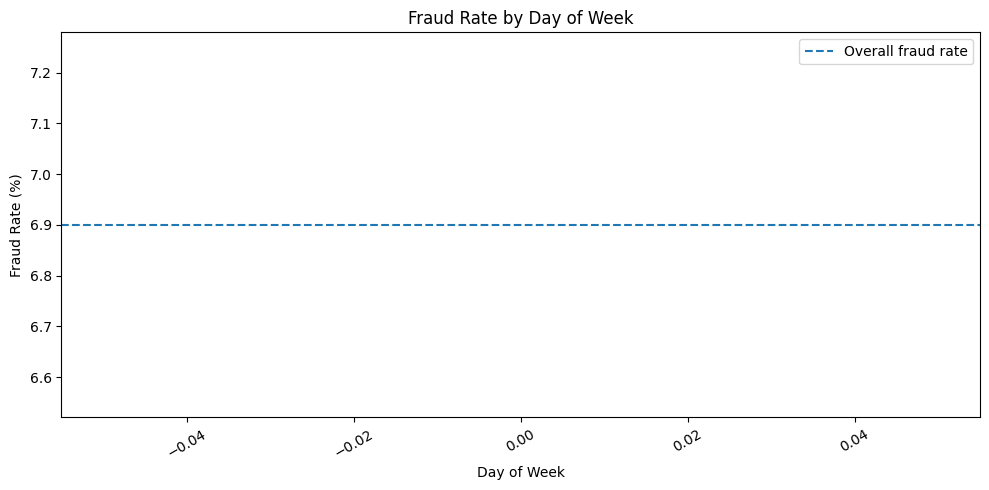

In [ ]:

# Fraud analysis by day of week

# Overall fraud rate
overall_fraud_rate = df_clean["is_fraud"].mean()

# Group transactions by day of week
day_analysis = (
    df_clean.groupby("day_of_week", observed=True)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

# Calculate fraud rate
day_analysis["fraud_rate_pct"] = (
    day_analysis["fraud_transactions"]
    / day_analysis["transactions"] * 100
).round(2)

# Calculate risk multiplier
day_analysis["risk_multiplier"] = (
    day_analysis["fraud_rate_pct"]
    / (overall_fraud_rate * 100)
).round(2)

# Add day names if day_of_week uses Monday=0 to Sunday=6
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

day_analysis["day_name"] = (
    day_analysis["day_of_week"].map(day_names)
)

display(
    day_analysis.sort_values(
        "fraud_rate_pct", ascending=False
    )
)

# Plot fraud rate by day
plt.figure(figsize=(10, 5))

plt.bar(
    day_analysis["day_name"],
    day_analysis["fraud_rate_pct"]
)

plt.axhline(
    overall_fraud_rate * 100,
    linestyle="--",
    label="Overall fraud rate"
)

plt.xlabel("Day of Week")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Day of Week")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

,is_weekend,transactions,fraud_transactions,fraud_rate_pct,risk_multiplier,day_type
0,0,703,50,7.11,1.03,NaN
1,1,297,19,6.40,0.93,NaN


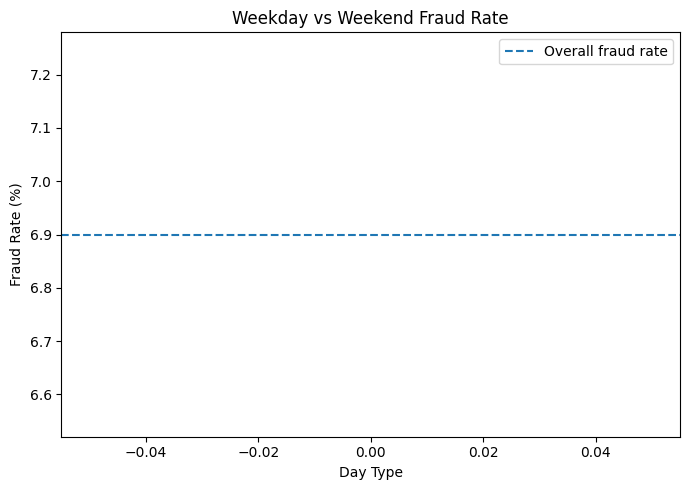

In [ ]:

# Fraud analysis: weekday vs weekend

weekend_analysis = (
    df_clean.groupby("is_weekend", observed=True)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

weekend_analysis["fraud_rate_pct"] = (
    weekend_analysis["fraud_transactions"]
    / weekend_analysis["transactions"] * 100
).round(2)

weekend_analysis["risk_multiplier"] = (
    weekend_analysis["fraud_rate_pct"]
    / (overall_fraud_rate * 100)
).round(2)

# Add readable labels
weekend_analysis["day_type"] = (
    weekend_analysis["is_weekend"]
    .map({True: "Weekend", False: "Weekday",
          1: "Weekend", 0: "Weekday"})
)

display(weekend_analysis)

# Plot comparison
plt.figure(figsize=(7, 5))

plt.bar(
    weekend_analysis["day_type"],
    weekend_analysis["fraud_rate_pct"]
)

plt.axhline(
    overall_fraud_rate * 100,
    linestyle="--",
    label="Overall fraud rate"
)

plt.xlabel("Day Type")
plt.ylabel("Fraud Rate (%)")
plt.title("Weekday vs Weekend Fraud Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
day_analysis["day_name"] = day_analysis["day_of_week"]

In [ ]:
weekend_analysis["day_type"] = (
    weekend_analysis["is_weekend"]
    .astype(str)
    .map({"0": "Weekday", "1": "Weekend"})
)

display(weekend_analysis)

,is_weekend,transactions,fraud_transactions,fraud_rate_pct,risk_multiplier,day_type
0,0,703,50,7.11,1.03,Weekday
1,1,297,19,6.40,0.93,Weekend


In [ ]:

# Transaction amount analysis

amount_analysis = (
    df_clean.groupby("is_fraud", observed=True)["amt"]
    .agg(
        transaction_count="count",
        mean_amount="mean",
        median_amount="median",
        min_amount="min",
        max_amount="max"
    )
    .round(2)
    .reset_index()
)

amount_analysis["transaction_type"] = (
    amount_analysis["is_fraud"]
    .map({0: "Legitimate", 1: "Fraudulent"})
)

display(amount_analysis)

,is_fraud,transaction_count,mean_amount,median_amount,min_amount,max_amount,transaction_type
0,0,931,103.50,40.73,1.88,2461.69,Legitimate
1,1,69,442.32,67.69,12.30,2481.19,Fraudulent


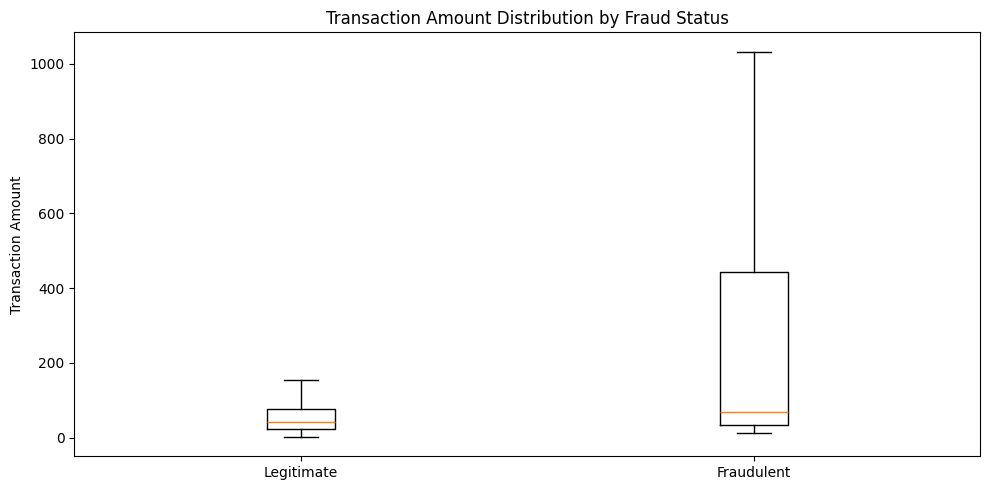

In [ ]:
#Visualize the amount distributions
import matplotlib.pyplot as plt

legitimate_amounts = df_clean.loc[
    df_clean["is_fraud"] == 0, "amt"
]

fraudulent_amounts = df_clean.loc[
    df_clean["is_fraud"] == 1, "amt"
]

plt.figure(figsize=(10, 5))

plt.boxplot(
    [legitimate_amounts, fraudulent_amounts],
    tick_labels=["Legitimate", "Fraudulent"],
    showfliers=False
)

plt.ylabel("Transaction Amount")
plt.title("Transaction Amount Distribution by Fraud Status")
plt.tight_layout()
plt.show()

In [ ]:
#Identify risky transaction amount ranges

import pandas as pd
import matplotlib.pyplot as plt

# Define transaction amount ranges
amount_bins = [0, 25, 50, 100, 250, 500, 1000, float("inf")]

amount_labels = [
    "0–25",
    "25–50",
    "50–100",
    "100–250",
    "250–500",
    "500–1000",
    "1000+"
]

df_clean["amount_band"] = pd.cut(
    df_clean["amt"],
    bins=amount_bins,
    labels=amount_labels,
    right=False
)

# Analyze fraud by amount band
amount_band_analysis = (
    df_clean.groupby("amount_band", observed=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

amount_band_analysis["fraud_rate_pct"] = (
    amount_band_analysis["fraud_transactions"]
    / amount_band_analysis["transactions"] * 100
).round(2)

amount_band_analysis["fraud_share_pct"] = (
    amount_band_analysis["fraud_transactions"]
    / df_clean["is_fraud"].sum() * 100
).round(2)

display(amount_band_analysis)


,amount_band,transactions,fraud_transactions,fraud_rate_pct,fraud_share_pct
0,0–25,258,6,2.33,8.70
1,25–50,328,22,6.71,31.88
2,50–100,236,15,6.36,21.74
3,100–250,118,6,5.08,8.70
4,250–500,14,3,21.43,4.35
5,500–1000,6,1,16.67,1.45
6,1000+,40,16,40.00,23.19


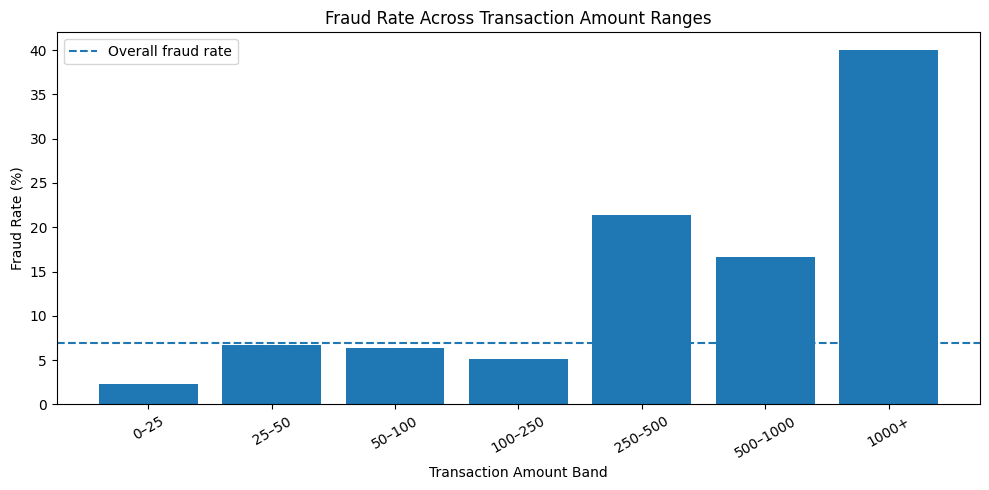

In [ ]:
#Plot the fraud rate by amount band

plt.figure(figsize=(10, 5))

plt.bar(
    amount_band_analysis["amount_band"].astype(str),
    amount_band_analysis["fraud_rate_pct"]
)

plt.axhline(
    df_clean["is_fraud"].mean() * 100,
    linestyle="--",
    label="Overall fraud rate"
)

plt.xlabel("Transaction Amount Band")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate Across Transaction Amount Ranges")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

High-value transactions stand out: The 1,000+ band has a 40% fraud rate, substantially above the overall dataset fraud rate of 6.9%.

Low-value fraud still matters: The 25–50 band contains 22 fraudulent transactions, the highest count among all bands. A monitoring strategy focused only on large transactions would miss many fraud cases.

Small samples require caution: The 250–500 and 500–1,000 bands contain only 14 and 6 transactions, respectively. Their fraud rates may be unstable.

The relationship is not perfectly linear: Fraud rates dip between 50–100 and 100–250 before rising in the higher bands. Higher amounts appear worth investigating, but amount alone does not explain every fraud case.

In [ ]:

# Geographic anomaly analysis

# Compare distance statistics by fraud status
distance_analysis = (
    df_clean.groupby("is_fraud", observed=True)["distance_km"]
    .agg(
        transaction_count="count",
        mean_distance="mean",
        median_distance="median",
        min_distance="min",
        max_distance="max"
    )
    .round(2)
    .reset_index()
)

distance_analysis["transaction_type"] = (
    distance_analysis["is_fraud"]
    .map({0: "Legitimate", 1: "Fraudulent"})
)

display(distance_analysis)

# Check missing values
print(
    "Missing distance values:",
    df_clean["distance_km"].isnull().sum()
)

,is_fraud,transaction_count,mean_distance,median_distance,min_distance,max_distance,transaction_type
0,0,931,199.33,187.76,6.47,573.18,Legitimate
1,1,69,233.05,228.96,44.52,472.59,Fraudulent


Missing distance values: 0


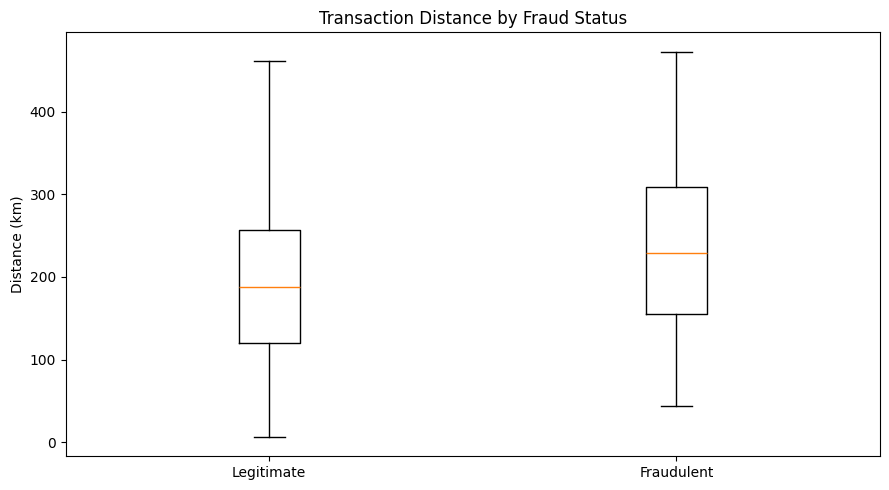

In [ ]:
#Visualize the distance distributions
import matplotlib.pyplot as plt

legitimate_distance = df_clean.loc[
    df_clean["is_fraud"] == 0, "distance_km"
].dropna()

fraudulent_distance = df_clean.loc[
    df_clean["is_fraud"] == 1, "distance_km"
].dropna()

plt.figure(figsize=(9, 5))

plt.boxplot(
    [legitimate_distance, fraudulent_distance],
    tick_labels=["Legitimate", "Fraudulent"],
    showfliers=False
)

plt.ylabel("Distance (km)")
plt.title("Transaction Distance by Fraud Status")
plt.tight_layout()
plt.show()

In [ ]:
#Analyze fraud rates by distance band

# Create distance bands
distance_bins = [0, 10, 50, 100, 250, float("inf")]

distance_labels = [
    "0–10 km",
    "10–50 km",
    "50–100 km",
    "100–250 km",
    "250+ km"
]

df_clean["distance_band"] = pd.cut(
    df_clean["distance_km"],
    bins=distance_bins,
    labels=distance_labels,
    right=False
)

# Calculate fraud metrics by distance band
distance_band_analysis = (
    df_clean.groupby("distance_band", observed=False)
    .agg(
        transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

distance_band_analysis["fraud_rate_pct"] = (
    distance_band_analysis["fraud_transactions"]
    / distance_band_analysis["transactions"] * 100
).round(2)

distance_band_analysis["fraud_share_pct"] = (
    distance_band_analysis["fraud_transactions"]
    / df_clean["is_fraud"].sum() * 100
).round(2)

display(distance_band_analysis)

,distance_band,transactions,fraud_transactions,fraud_rate_pct,fraud_share_pct
0,0–10 km,1,0,0.00,0.00
1,10–50 km,41,1,2.44,1.45
2,50–100 km,133,6,4.51,8.70
3,100–250 km,543,31,5.71,44.93
4,250+ km,282,31,10.99,44.93


,distance_band,transactions,fraud_transactions,fraud_rate_pct,fraud_share_pct
0,0–10 km,1,0,0.00,0.00
1,10–50 km,41,1,2.44,1.45
2,50–100 km,133,6,4.51,8.70
3,100–250 km,543,31,5.71,44.93
4,250+ km,282,31,10.99,44.93


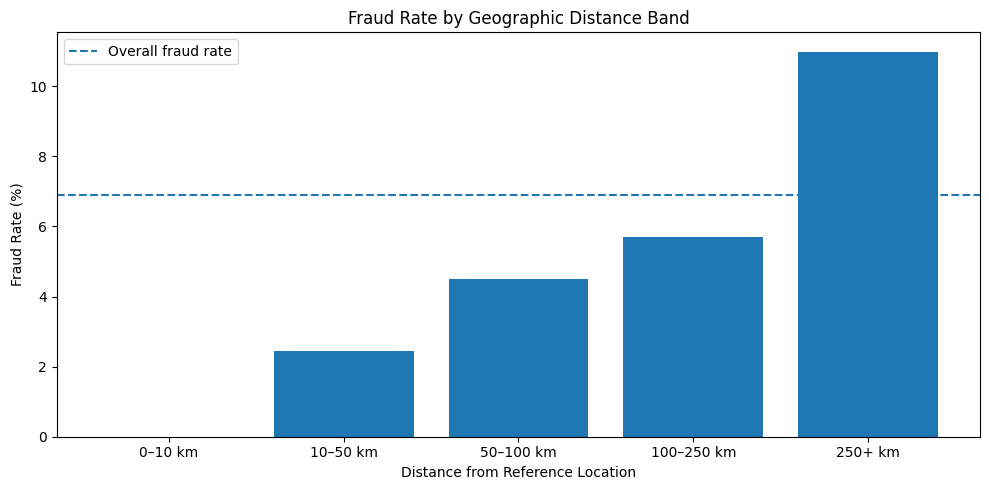

In [ ]:

# Analyze fraud by geographic distance bands

distance_bins = [0, 10, 50, 100, 250, float("inf")]

distance_labels = [
    "0–10 km",
    "10–50 km",
    "50–100 km",
    "100–250 km",
    "250+ km"
]

df_clean["distance_band"] = pd.cut(
    df_clean["distance_km"],
    bins=distance_bins,
    labels=distance_labels,
    right=False
)

distance_band_analysis = (
    df_clean.groupby("distance_band", observed=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

distance_band_analysis["fraud_rate_pct"] = (
    distance_band_analysis["fraud_transactions"]
    / distance_band_analysis["transactions"] * 100
).round(2)

distance_band_analysis["fraud_share_pct"] = (
    distance_band_analysis["fraud_transactions"]
    / df_clean["is_fraud"].sum() * 100
).round(2)

display(distance_band_analysis)

# Plot fraud rate by distance band
plt.figure(figsize=(10, 5))

plt.bar(
    distance_band_analysis["distance_band"].astype(str),
    distance_band_analysis["fraud_rate_pct"]
)

plt.axhline(
    df_clean["is_fraud"].mean() * 100,
    linestyle="--",
    label="Overall fraud rate"
)

plt.xlabel("Distance from Reference Location")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Geographic Distance Band")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# Age-based fraud analysis

age_analysis = (
    df_clean.groupby("is_fraud", observed=True)["age"]
    .agg(
        transaction_count="count",
        mean_age="mean",
        median_age="median",
        min_age="min",
        max_age="max"
    )
    .round(2)
    .reset_index()
)

age_analysis["transaction_type"] = (
    age_analysis["is_fraud"]
    .map({0: "Legitimate", 1: "Fraudulent"})
)

display(age_analysis)

print("Missing age values:", df_clean["age"].isnull().sum())

print("\nAge distribution:")
print(df_clean["age"].describe())

,is_fraud,transaction_count,mean_age,median_age,min_age,max_age,transaction_type
0,0,931,43.59,43.0,24,65,Legitimate
1,1,69,44.64,44.0,24,64,Fraudulent


Missing age values: 0

Age distribution:
count    1000.000000
mean       43.659000
std        11.883937
min        24.000000
25%        34.000000
50%        43.000000
75%        54.000000
max        65.000000
Name: age, dtype: float64


In [ ]:

# Define age bands
age_bins = [0, 18, 25, 35, 45, 55, 65, float("inf")]

age_labels = [
    "Under 18",
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65+"
]

df_clean["age_band"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Aggregate fraud metrics by age group
age_band_analysis = (
    df_clean.groupby("age_band", observed=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

age_band_analysis["fraud_rate_pct"] = (
    age_band_analysis["fraud_transactions"]
    / age_band_analysis["transactions"] * 100
).round(2)

age_band_analysis["fraud_share_pct"] = (
    age_band_analysis["fraud_transactions"]
    / df_clean["is_fraud"].sum() * 100
).round(2)

display(age_band_analysis)

,age_band,transactions,fraud_transactions,fraud_rate_pct,fraud_share_pct
0,Under 18,0,0,NaN,0.00
1,18–24,26,1,3.85,1.45
2,25–34,248,18,7.26,26.09
3,35–44,259,17,6.56,24.64
4,45–54,234,14,5.98,20.29
5,55–64,231,19,8.23,27.54
6,65+,2,0,0.00,0.00


Business insights

Ages 55–64 have the highest observed fraud rate among the populated age groups, at 8.23%. This is only modestly above the overall rate of 6.90%.

Ages 25–34 account for 18 fraud cases, while ages 55–64 account for 19. Both groups contribute a meaningful share of observed fraud.

The average ages are similar: 44.64 for fraudulent transactions and 43.59 for legitimate transactions. This suggests age is not a clear standalone separator.

The smallest groups are inconclusive: Ages 18–24 contain only 26 transactions, while the 65+ group contains only 2. Their rates should not drive alert decisions.

In [ ]:

# Candidate rule-based fraud alerts
# These are exploratory rules, not a production model.

df_clean["alert_high_amount"] = (
    df_clean["amt"] >= 1000
)

df_clean["alert_long_distance"] = (
    df_clean["distance_km"] >= 250
)

df_clean["alert_high_risk_hour"] = (
    df_clean["hour"].isin([22, 0, 1, 2])
)

# Count the number of triggered signals
alert_columns = [
    "alert_high_amount",
    "alert_long_distance",
    "alert_high_risk_hour"
]

df_clean["alert_signal_count"] = (
    df_clean[alert_columns].sum(axis=1)
)

# Assign an exploratory alert category
df_clean["alert_category"] = "No candidate signal"

df_clean.loc[
    df_clean["alert_signal_count"] == 1,
    "alert_category"
] = "One signal"

df_clean.loc[
    df_clean["alert_signal_count"] >= 2,
    "alert_category"
] = "Multiple signals"

# Summarize results by alert category
alert_analysis = (
    df_clean.groupby("alert_category", observed=True)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

alert_analysis["fraud_rate_pct"] = (
    alert_analysis["fraud_transactions"]
    / alert_analysis["transactions"] * 100
).round(2)

display(alert_analysis)

,alert_category,transactions,fraud_transactions,fraud_rate_pct
0,Multiple signals,71,18,25.35
1,No candidate signal,574,17,2.96
2,One signal,355,34,9.58


Business interpretation

Multiple signals: 25.35% of transactions in this group are fraudulent, making it the strongest of the three categories.

One signal: The fraud rate is 9.58%, which is higher than the overall dataset rate of 6.90%.

No candidate signal: The rate is lower at 2.96%, but the group still contains 17 fraudulent transactions.

In [ ]:

# Evaluate each candidate fraud alert rule

rule_columns = {
    "High amount (1000+)": "alert_high_amount",
    "Long distance (250+ km)": "alert_long_distance",
    "High-risk hour": "alert_high_risk_hour"
}

rule_results = []

total_frauds = df_clean["is_fraud"].sum()
total_legitimate = (df_clean["is_fraud"] == 0).sum()

for rule_name, rule_column in rule_columns.items():
    flagged = df_clean[rule_column]
    flagged_transactions = int(flagged.sum())

    fraud_caught = int(
        df_clean.loc[flagged, "is_fraud"].sum()
    )

    legitimate_flagged = int(
        ((df_clean["is_fraud"] == 0) & flagged).sum()
    )

    rule_results.append({
        "rule": rule_name,
        "transactions_flagged": flagged_transactions,
        "fraud_caught": fraud_caught,
        "alert_precision_pct": round(
            fraud_caught / flagged_transactions * 100, 2
        ) if flagged_transactions else 0,
        "fraud_detection_rate_pct": round(
            fraud_caught / total_frauds * 100, 2
        ) if total_frauds else 0,
        "legitimate_transactions_flagged": legitimate_flagged,
        "legitimate_flag_rate_pct": round(
            legitimate_flagged / total_legitimate * 100, 2
        ) if total_legitimate else 0
    })

rule_performance = pd.DataFrame(rule_results)

display(
    rule_performance.sort_values(
        "fraud_detection_rate_pct",
        ascending=False
    )
)

,rule,transactions_flagged,fraud_caught,alert_precision_pct,fraud_detection_rate_pct,legitimate_transactions_flagged,legitimate_flag_rate_pct
1,Long distance (250+ km),282,31,10.99,44.93,251,26.96
2,High-risk hour,179,27,15.08,39.13,152,16.33
0,High amount (1000+),40,16,40.00,23.19,24,2.58


In [ ]:

# Evaluate combined fraud alert strategies

alert_strategies = {
    "At least 1 signal": (
        df_clean["alert_signal_count"] >= 1
    ),
    "At least 2 signals": (
        df_clean["alert_signal_count"] >= 2
    ),
    "All 3 signals": (
        df_clean["alert_signal_count"] == 3
    )
}

total_transactions = len(df_clean)
total_frauds = int(df_clean["is_fraud"].sum())
total_legitimate = total_transactions - total_frauds

combined_results = []

for strategy_name, flagged in alert_strategies.items():
    transactions_flagged = int(flagged.sum())

    fraud_caught = int(
        df_clean.loc[flagged, "is_fraud"].sum()
    )

    legitimate_flagged = int(
        transactions_flagged - fraud_caught
    )

    combined_results.append({
        "strategy": strategy_name,
        "transactions_flagged": transactions_flagged,
        "fraud_caught": fraud_caught,
        "legitimate_flagged": legitimate_flagged,
        "alert_precision_pct": round(
            fraud_caught / transactions_flagged * 100, 2
        ) if transactions_flagged else 0,
        "fraud_detection_rate_pct": round(
            fraud_caught / total_frauds * 100, 2
        ) if total_frauds else 0,
        "legitimate_flag_rate_pct": round(
            legitimate_flagged / total_legitimate * 100, 2
        ) if total_legitimate else 0
    })

combined_performance = pd.DataFrame(combined_results)

display(combined_performance)

,strategy,transactions_flagged,fraud_caught,legitimate_flagged,alert_precision_pct,fraud_detection_rate_pct,legitimate_flag_rate_pct
0,At least 1 signal,426,52,374,12.21,75.36,40.17
1,At least 2 signals,71,18,53,25.35,26.09,5.69
2,All 3 signals,4,4,0,100.00,5.80,0.00


In [ ]:

# Create mutually exclusive alert priority levels

df_clean["alert_priority"] = "No candidate signal"

df_clean.loc[
    df_clean["alert_signal_count"] == 1,
    "alert_priority"
] = "Medium"

df_clean.loc[
    df_clean["alert_signal_count"] == 2,
    "alert_priority"
] = "High"

df_clean.loc[
    df_clean["alert_signal_count"] == 3,
    "alert_priority"
] = "Critical"


# Summarize alert performance by priority

priority_summary = (
    df_clean.groupby("alert_priority", observed=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_cases=("is_fraud", "sum"),
        avg_transaction_amount=("amt", "mean")
    )
    .reset_index()
)

priority_summary["legitimate_transactions"] = (
    priority_summary["transactions"]
    - priority_summary["fraud_cases"]
)

priority_summary["fraud_rate_pct"] = (
    priority_summary["fraud_cases"]
    / priority_summary["transactions"] * 100
).round(2)

priority_summary["share_of_all_frauds_pct"] = (
    priority_summary["fraud_cases"]
    / df_clean["is_fraud"].sum() * 100
).round(2)

display(priority_summary)

,alert_priority,transactions,fraud_cases,avg_transaction_amount,legitimate_transactions,fraud_rate_pct,share_of_all_frauds_pct
0,Critical,4,4,1729.157500,0,100.00,5.80
1,High,67,14,507.043134,53,20.90,20.29
2,Medium,355,34,147.414761,321,9.58,49.28
3,No candidate signal,574,17,58.641463,557,2.96,24.64


20.90% fraud rate in High priority

High-priority transactions had a fraud rate about seven times the 2.96% rate among transactions with no candidate signal. Critical priority had a 100% fraud rate, but included only four transactions.

Business insights

Critical: All four transactions were fraudulent. Prioritize these for immediate investigation, but don't assume 100% precision will hold on new data.

High: 14 of 67 transactions were fraudulent. These could be queued for prompt review.

Medium: This group captured 34 fraud cases, or 49.28% of all fraud. Although its fraud rate was lower, it contained the largest number of fraud cases among the alert tiers.

No candidate signal: 17 fraud cases still occurred here. The three rules do not detect every fraud pattern, so transactions without these signals should not automatically be considered safe.

The priority system is a useful candidate alert framework, not a validated production system yet. The thresholds and performance should be checked on new, unseen transactions before deployment.

In [33]:

# Export the final analyzed dataset for Power BI

powerbi_df = df_clean.copy()

powerbi_df.to_csv(
    "fraud_analysis_powerbi.csv",
    index=False
)

print("CSV file exported successfully!")
print("Dataset shape:", powerbi_df.shape)

CSV file exported successfully!
Dataset shape: (1000, 39)


In [34]:

import os

print("CSV saved at:", os.path.abspath("fraud_analysis_powerbi.csv"))

CSV saved at: /content/fraud_analysis_powerbi.csv


In [ ]:

import pandas as pd

# Start with the analyzed dataset
powerbi_df = df_clean.copy()

# Create a proper transaction date if the timestamp exists
if "trans_date_trans_time" in powerbi_df.columns:
    powerbi_df["trans_date_trans_time"] = pd.to_datetime(
        powerbi_df["trans_date_trans_time"],
        errors="coerce"
    )

    powerbi_df["transaction_date"] = (
        powerbi_df["trans_date_trans_time"].dt.date
    )

# Keep the columns that exist in the dataset
desired_columns = [
    "trans_date_trans_time",
    "transaction_date",
    "trans_num",
    "category",
    "amt",
    "gender",
    "city",
    "state",
    "city_pop",
    "hour",
    "day_of_week",
    "is_weekend",
    "month",
    "time_period",
    "age",
    "distance_km",
    "is_fraud",
    "alert_high_amount",
    "alert_long_distance",
    "alert_high_risk_hour",
    "alert_signal_count",
    "alert_category",
    "alert_priority"
]

available_columns = [
    col for col in desired_columns
    if col in powerbi_df.columns
]

powerbi_df = powerbi_df[available_columns].copy()

# Validate the Power BI dataset
print("Dataset shape:", powerbi_df.shape)
print("Duplicate rows:", powerbi_df.duplicated().sum())
print("Missing values by column:")
display(powerbi_df.isnull().sum().to_frame("missing_values"))

print("Preview of Power BI dataset:")
display(powerbi_df.head())

# Export to CSV
powerbi_df.to_csv(
    "fraud_analysis_powerbi.csv",
    index=False
)

print("Export complete: fraud_analysis_powerbi.csv")

Dataset shape: (1000, 23)
Duplicate rows: 0
Missing values by column:


,missing_values
trans_date_trans_time,0
transaction_date,0
trans_num,0
category,0
amt,0
gender,0
city,0
state,0
city_pop,0
hour,0


Preview of Power BI dataset:


,trans_date_trans_time,transaction_date,trans_num,category,amt,gender,city,state,city_pop,hour,...,time_period,age,distance_km,is_fraud,alert_high_amount,alert_long_distance,alert_high_risk_hour,alert_signal_count,alert_category,alert_priority
0,2025-01-01 00:15:00,2025-01-01,TXN100000000,food_delivery,43.51,F,Bhopal,GJ,2828217,0,...,Night,49,197.055947,0,False,False,True,1,One signal,Medium
1,2025-01-01 00:48:00,2025-01-01,TXN100000001,shopping_net,75.99,M,Bhopal,MP,1814239,0,...,Night,27,219.028681,0,False,False,True,1,One signal,Medium
2,2025-01-01 00:56:00,2025-01-01,TXN100000002,grocery_net,9.73,F,Indore,RJ,1389083,0,...,Night,45,221.976339,0,False,False,True,1,One signal,Medium
3,2025-01-01 04:06:00,2025-01-01,TXN100000003,health_fitness,134.58,M,Jaipur,MH,1260368,4,...,Night,63,152.519851,0,False,False,False,0,No candidate signal,No candidate signal
4,2025-01-01 04:20:00,2025-01-01,TXN100000004,grocery_net,75.26,M,Kolkata,UP,1790081,4,...,Night,47,83.149923,0,False,False,False,0,No candidate signal,No candidate signal


Export complete: fraud_analysis_powerbi.csv


In [35]:

from google.colab import files

# Export your analyzed dataset
powerbi_df.to_csv("fraud_analysis_powerbi.csv", index=False)

# Download the CSV to your computer
files.download("fraud_analysis_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>